# LLM Fine Tuning · Lesson 13 · Capstone: a governed release

The course trained one model on one task: a question about a table in, one SQLite query out, on
Qwen2.5-1.5B-Instruct. This lab does not teach a new method. It strings the decisions of the course into one release,
from the first decision to a rollback, and each step leaves a record that a reviewer could read later.

Seven questions are asked, each answered by something the notebook produces:

1. **Should we fine-tune at all?** A decision record: the baselines are measured first, and the rule for going ahead
   is written before they are measured.
2. **What exactly was the model trained on?** A data card: source, licence, cleaning counts, split by table, leakage
   checks and a hash of the data.
3. **What would make us say no?** The gate: thresholds written to a file and hashed before any candidate is trained
   or scored. Then two candidates are trained from a config file with a fixed seed.
4. **Does a candidate pass?** The gate on 500 held-out questions: execution accuracy on populated tables, a paired
   test against the best baseline, a regression check, a format and safety check, speed and a check per segment.
   A control candidate that should fail is run through the same gate.
5. **What is released?** A release record and a model card: data hash, config, metrics, gate results, adapter hash and
   the pinned revision of the base model.
6. **Does it hold on traffic that looks different?** A canary and shadow simulation on a second held-out slice
   whose mix of questions differs from the gate set.
7. **Can we go back?** A rollback that is checked, not assumed: the previous version reproduces its recorded outputs,
   and a damaged adapter is refused.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. It takes about 40 minutes on a T4, of
which about 20 are two training runs (one on 1,000 examples, one on 8,000, the same recipe as lesson 4). Everything else
is generation and scoring. If no candidate passes the gate, section 4 stops the notebook on purpose.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/4-ship/13-capstone).

## 0. Install, load and rebuild the splits

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import sqlite3
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from huggingface_hub import HfApi
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "cuda"
DTYPE = torch.float16        # a T4 has no bfloat16 (lesson 2)
N_GATE = 500                 # held-out questions the gate is decided on
N_CANARY = 400               # a second held-out slice that plays the live traffic
N_PROBE = 96                 # the first questions of the gate set, re-run to prove rollback (a multiple of the batch of 16)
N_VAL = 200                  # validation examples, used for the loss curve only
N_TRAIN_FULL = 8000          # lesson 4's training set
N_TRAIN_PILOT = 1000         # a cheaper candidate to compare it with
DB_ROWS = 30                 # rows put in every table when a query is executed
GB = 1e9
RELEASE = "release"          # every record the notebook writes goes here
for d in [RELEASE, "adapters", "runs"]:
    os.makedirs(d, exist_ok=True)


def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()


def sha256_json(obj):
    """A stable hash of any JSON-able object: sorted keys, no white space."""
    return sha256_bytes(json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode())


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, obj):
    with open(path, "w") as f:
        json.dump(obj, f, indent=1, sort_keys=True, ensure_ascii=False, default=str)
    return sha256_file(path)


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


# The base model is pinned to the exact revision that exists today, and every load below passes it.
info = HfApi().model_info(MODEL_ID)
BASE_REV = info.sha
BASE_LICENCE = (info.card_data.license if info.card_data is not None else None)
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print(f"base model {MODEL_ID} at revision {BASE_REV} (licence per its model card: {BASE_LICENCE})")

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2
GPU: Tesla T4
base model Qwen/Qwen2.5-1.5B-Instruct at revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 (licence per its model card: apache-2.0)


The data is rebuilt with the same code and seed as lessons 3 and 4: drop gold queries that fail in SQLite, drop exact
duplicates, then split **by table**. The cleaning counts are kept, because the data card in section 2 reports them.

In [3]:
# Pinned to the same commit of the dataset as lesson 3. The licence is CC BY 4.0 (its dataset card, at this commit).
DATA_COMMIT = "9d80a6a118b838d9defc3798d659a54a2ac2ff37"
URL = f"https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/{DATA_COMMIT}/sql_create_context_v4.json"
data = pd.DataFrame(json.load(urllib.request.urlopen(URL)))


def runs(context, sql):
    """Return None if the query runs against the (empty) schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
named = ~table.str.fullmatch(r"table_name_\d+")            # WikiSQL's re-used names say nothing about identity
data["group"] = np.where(named, table, "row" + data.index.astype(str))
data["segment"] = np.where(named, "named tables (Spider style)", "table_name_N (WikiSQL style)")

n_raw = len(data)
ok = data[data["error"].isna()]
clean = ok.drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
cleaning = {"raw examples": n_raw, "dropped: gold query fails in SQLite": n_raw - len(ok),
            "dropped: exact duplicates": len(ok) - len(clean), "kept": len(clean)}
print(cleaning)

uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
clean["id"] = clean.index
counts = clean["split"].value_counts().to_dict()
print(counts)
assert counts == {"train": 69170, "test": 3923, "validation": 3817}, "differs from lessons 3 and 4"

rows = {s: clean[clean["split"] == s].to_dict("records") for s in ["train", "validation", "test"]}

{'raw examples': 78577, 'dropped: gold query fails in SQLite': 1667, 'dropped: exact duplicates': 0, 'kept': 76910}
{'train': 69170, 'test': 3923, 'validation': 3817}


### The helpers every later step uses

Three things are needed that lesson 4 did not have, because it scored on **empty** tables:

- **Populated tables.** `make_db` creates the schema from the `CREATE TABLE` text and puts rows in every table. Text
  values are drawn from the literals in the gold query, so a `WHERE name = 'x'` finds rows; the other values are random.
  Two copies with different seeds are built for each question, and a query only counts as right if it returns the
  same rows as the gold query on both. A wrong query can agree with the gold query by chance on one random table; it
  rarely does on two.
- **Execution accuracy.** The predicted query and the gold query are run on the populated tables and their result rows
  are compared (as a set of rows, or in order when the gold query has an `ORDER BY`). Questions whose gold query
  returns no rows are left out of this metric, because an empty result matches too easily. Exact match (lesson 4) is
  kept next to it, because exact match is strict where execution accuracy is lenient.
- **Format and safety flags.** A reply is well formed if it is one `SELECT` (or `WITH`) statement with no Markdown
  fence and no prose around it. A reply is unsafe if it contains a statement that would write to the database.
  Whatever the model writes is only ever executed on a throwaway database that is set read-only.

In [4]:
SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form, as TRL's SFTTrainer expects it."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


def clean_sql(text):
    """Strip white space and a Markdown code fence, if the model wrote one."""
    return re.sub(r"^```(?:sql)?\s*|\s*```$", "", text.strip(), flags=re.I).strip()


def normalise(sql):
    sql = re.sub(r"\s+", " ", sql.strip().lower()).strip()
    return sql.rstrip(";").strip().replace('"', "'")


# ---- populated tables ----
WORDS = ["alpha", "beta", "gamma", "delta", "north", "south", "red", "blue", "paris", "tokyo", "smith", "lee", "gold"]


def literals(sql):
    """String and number literals written in a query."""
    strs = [a or b for a, b in re.findall(r"'((?:[^']|'')*)'|\"([^\"]*)\"", sql)]
    bare = re.sub(r"'[^']*'|\"[^\"]*\"", "", sql)
    nums = [float(x) if "." in x else int(x) for x in re.findall(r"(?<![\w.])\d+(?:\.\d+)?(?![\w])", bare)]
    return [s.strip("%") for s in strs], nums


def affinity(sql_type):
    """SQLite's column affinity rules, reduced to text or number."""
    t = sql_type.upper()
    if "INT" in t or any(k in t for k in ("REAL", "FLOA", "DOUB")):
        return "number"
    return "text" if any(k in t for k in ("CHAR", "CLOB", "TEXT", "BLOB")) or t == "" else "number"


def make_db(r, seed):
    """A throwaway database with this question's schema and DB_ROWS rows per table. Deterministic given the seed."""
    rng = random.Random(f"{seed}|{r['context']}|{r['answer']}")
    con = sqlite3.connect(":memory:")
    for statement in r["context"].split(";"):
        if statement.strip():
            con.execute(statement)
    strs, nums = literals(r["answer"])
    for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'").fetchall():
        cols = con.execute(f'PRAGMA table_info("{t}")').fetchall()
        for _ in range(DB_ROWS):
            vals = []
            for _, _, sql_type, *_ in cols:
                if affinity(sql_type) == "number":
                    near = rng.choice(nums) + rng.choice([-2, -1, 0, 0, 1, 2, 5]) if nums and rng.random() < 0.6 else None
                    vals.append(near if near is not None else rng.randint(0, 100))
                else:
                    pool = strs + [str(x) for x in nums]
                    vals.append(rng.choice(pool) if pool and rng.random() < 0.5 else rng.choice(WORDS) + str(rng.randint(0, 9)))
            con.execute(f'INSERT INTO "{t}" VALUES ({",".join("?" * len(vals))})', vals)
    con.commit()
    con.execute("PRAGMA query_only = ON")        # from here on nothing can write, whatever the model produced
    return con


def fetch(con, sql, limit_s=2.0):
    """Rows of a query, or None if it fails or runs longer than limit_s seconds."""
    start = time.perf_counter()
    con.set_progress_handler(lambda: int(time.perf_counter() - start > limit_s), 10000)
    try:
        return con.execute(sql).fetchall()
    except sqlite3.Error:
        return None
    finally:
        con.set_progress_handler(None, 0)


def same_rows(gold_rows, pred_rows, ordered):
    if pred_rows is None:
        return False
    fix = lambda rs: [tuple(float(v) if isinstance(v, (int, float)) else v for v in row) for row in rs]
    g, p = fix(gold_rows), fix(pred_rows)
    return g == p if ordered else sorted(g, key=repr) == sorted(p, key=repr)


DB_SEEDS = (0, 1)


def execution(r, sql):
    """(matches gold on both populated copies, gold returned rows on both copies)."""
    if not sql:
        return False, True
    ordered = bool(re.search(r"\border\s+by\b", r["answer"], re.I))
    match, nonempty = True, True
    for s in DB_SEEDS:
        con = make_db(r, s)
        g = fetch(con, r["answer"])
        p = fetch(con, sql)
        con.close()
        nonempty &= bool(g)
        match &= g is not None and same_rows(g, p, ordered)
    return match, nonempty


# ---- format and safety ----
WRITE = re.compile(r"\b(insert|update|delete|drop|alter|create|attach|detach|pragma|vacuum|reindex)\b", re.I)


def flags(raw, sql):
    body = re.sub(r"'(?:[^']|'')*'|\"[^\"]*\"", "''", sql).strip().rstrip(";")
    fenced = raw.strip() != sql
    single = ";" not in body
    select_only = bool(re.match(r"\s*(select|with)\b", body, re.I))
    # One SELECT cannot write. Anything else that names a write keyword is counted as unsafe; prose is badly formed, not unsafe.
    unsafe = bool(WRITE.search(body)) and not (select_only and single)
    return {"fenced": fenced, "single": single, "select_only": select_only,
            "unsafe": unsafe, "format_ok": (not fenced) and single and select_only}


def score(rows_, generated):
    """Per-example metrics for a list of generated answers."""
    out = []
    for r, g in zip(rows_, generated):
        sql = clean_sql(g)
        error = "empty answer" if not sql else runs(r["context"], sql)
        match, nonempty = execution(r, sql)
        out.append({"sql": sql, "error": error, "runs": error is None, "exact": normalise(sql) == normalise(r["answer"]),
                    "exec": match, "gold_nonempty": nonempty, "segment": r["segment"], **flags(g, sql)})
    return pd.DataFrame(out)


def summary(df):
    ne = df["gold_nonempty"]
    return {"runs": df["runs"].mean(), "exact": df["exact"].mean(), "exec": df.loc[ne, "exec"].mean(),
            "n exec": int(ne.sum()), "format ok": df["format_ok"].mean(), "unsafe": int(df["unsafe"].sum())}


def ci(p, n):
    """95% interval half-width on a rate (lesson 3)."""
    return 1.96 * math.sqrt(p * (1 - p) / max(n, 1))


def sign_test_p(only_a, only_b):
    """Exact two-sided sign test on the questions where two systems disagree (McNemar's exact test)."""
    n, k = only_a + only_b, min(only_a, only_b)
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)


def digest(answers):
    return sha256_bytes("\n\x1f\n".join(answers).encode())


# ---- generation (lesson 4) ----
@torch.inference_mode()
def generate(model, tok, prompts, batch=16, max_new_tokens=128):
    """Greedy answers for a list of chat prompts, batched with left padding. Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=BASE_REV, padding_side="left")


def load_base():
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=BASE_REV, torch_dtype=DTYPE, device_map={"": DEVICE})

Before anything is trusted, the checker is checked on a table small enough to read. Three candidate queries are
compared with one gold query. The first is the same query written differently, so exact match calls it wrong and
execution accuracy calls it right. The other two change the meaning, so both metrics call them wrong.

In [5]:
demo = {"context": "CREATE TABLE head (age INTEGER)", "answer": "SELECT COUNT(*) FROM head WHERE age > 56"}
con = make_db(demo, 0)
print("rows in the populated table (first 8 of", DB_ROWS, "):", con.execute("SELECT age FROM head LIMIT 8").fetchall())
con.close()
cases = {
    "same meaning, written differently": "SELECT COUNT(1) FROM head WHERE age > 56",
    "changes the operator": "SELECT COUNT(*) FROM head WHERE age >= 56",
    "drops the condition": "SELECT COUNT(*) FROM head",
}
shown = []
for name, sql in cases.items():
    match, _ = execution(demo, sql)
    shown.append({"candidate": name, "exact match": normalise(sql) == normalise(demo["answer"]), "execution match": match})
print(pd.DataFrame(shown).to_string(index=False))
assert [(s["exact match"], s["execution match"]) for s in shown] == [(False, True), (False, False), (False, False)]
print("\nformat flags for a fenced answer and for a write statement:")
for raw in ["```sql\nSELECT 1\n```", "DROP TABLE head; SELECT 1"]:
    print(f"  {raw!r:34} ->", {k: v for k, v in flags(raw, clean_sql(raw)).items() if k in ("format_ok", "unsafe")})

rows in the populated table (first 8 of 30 ): [(58,), (55,), (61,), (38,), (2,), (54,), (61,), (58,)]
                        candidate  exact match  execution match
same meaning, written differently        False             True
             changes the operator        False            False
              drops the condition        False            False

format flags for a fenced answer and for a write statement:
  '```sql\nSELECT 1\n```'            -> {'unsafe': False, 'format_ok': False}
  'DROP TABLE head; SELECT 1'        -> {'unsafe': True, 'format_ok': False}


## 1. Should we fine-tune at all? The decision record

Lesson 1's rule: measure the baseline first, on the examples the tuned model will be measured on. The rule for going
ahead is written down **before** the baselines are measured, so the number cannot move the rule.

Two baselines, both with no training: the prompt of lesson 3 on its own (zero-shot) and the same prompt after three
fixed solved examples (3-shot). Showing the model the format is the cheapest alternative to training, so it is the fair
rival. The better of the two becomes the **incumbent**: the thing that is in production today and the thing a fine-tune
has to beat. Questions are drawn at random with a fixed seed from the test split into two disjoint groups: the **gate**
set (500 questions, decides the release) and the **canary** slice (plays live traffic in section 6). The first questions
of the gate set are also kept as a **probe** for the rollback drill in section 7. None of them is in the training data.

In [6]:
# Written, hashed and saved BEFORE any baseline is measured.
DECISION = {
    "task": "a question about a table in, one SQLite query out",
    "success metric": "execution accuracy on populated tables (gold query returns rows), gate set",
    "go rule": "fine-tune only if the best baseline's execution accuracy is below this value",
    "go threshold": 0.90,
    "required margin over the best baseline, points": 5.0,
    "alternatives considered": ["zero-shot prompt", "3-shot prompt", "LoRA fine-tune of the same model"],
    "declared before measuring": True,
}
DECISION_SHA = write_json(f"{RELEASE}/decision_rule.json", DECISION)
print("decision rule saved, sha256", DECISION_SHA[:16])

test_pool = rows["test"]
gate = random.Random(SEED).sample(test_pool, N_GATE)                       # the same 500 as lessons 4 and 5
used = {r["id"] for r in gate}
rest = [r for r in test_pool if r["id"] not in used]
# The canary slice is drawn with a different mix on purpose: live traffic is never the benchmark's mix.
want_wiki = int(0.35 * N_CANARY)
wiki = [r for r in rest if r["segment"].startswith("table_name")]
spider = [r for r in rest if not r["segment"].startswith("table_name")]
canary = random.Random(SEED + 1).sample(wiki, want_wiki) + random.Random(SEED + 1).sample(spider, N_CANARY - want_wiki)
random.Random(SEED + 2).shuffle(canary)
probe = gate[:N_PROBE]
assert not used & {r["id"] for r in canary}, "gate and canary overlap"
assert not {r["id"] for r in rows["train"]} & (used | {r["id"] for r in canary}), "train and test overlap"
for name, rs in [("gate", gate), ("canary", canary)]:
    print(f"{name:7s}", len(rs), "questions;", pd.Series([r["segment"] for r in rs]).value_counts().to_dict())

shots = random.Random(SEED).sample(rows["train"], 3)


def zero_shot(r):
    return messages(r)["prompt"]


def three_shot(r):
    """The same prompt, with three solved examples before the real question as earlier turns."""
    prompt = messages(r)["prompt"]
    turns = []
    for s in shots:
        m = messages(s)
        turns += [m["prompt"][1], m["completion"][0]]
    return prompt[:1] + turns + prompt[1:]

decision rule saved, sha256 18315a34c651395d
gate    500 questions; {'table_name_N (WikiSQL style)': 329, 'named tables (Spider style)': 171}
canary  400 questions; {'named tables (Spider style)': 260, 'table_name_N (WikiSQL style)': 140}


In [7]:
ANS, SCORED, MS = {}, {}, {}          # per system: answers, per-example scores, ms per example (gate set)
PROMPT = {"zero-shot": zero_shot, "3-shot": three_shot}

base = load_base().eval()
for name, build in PROMPT.items():
    ANS[name], MS[name] = generate(base, tok, [build(r) for r in gate])
    SCORED[name] = score(gate, ANS[name])
del base
free_gpu()

rep = pd.DataFrame({k: summary(SCORED[k]) for k in PROMPT}).T
rep["ms per example"] = pd.Series(MS)
print(rep.round(3).to_string())

best = max(PROMPT, key=lambda k: summary(SCORED[k])["exec"])
INCUMBENT = best
best_exec = summary(SCORED[best])["exec"]
BAR = best_exec + DECISION["required margin over the best baseline, points"] / 100
go = best_exec < DECISION["go threshold"]
print(f"\nincumbent: {INCUMBENT}, execution accuracy {best_exec:.1%}")
print(f"rule: fine-tune only if the best baseline is below {DECISION['go threshold']:.0%} -> {'GO' if go else 'NO GO'}")
print(f"the bar a fine-tune must clear: execution accuracy of at least {BAR:.1%}, and a paired test (section 4)")
decision_record = {**DECISION, "decision rule sha256": DECISION_SHA, "baselines": rep.round(4).to_dict("index"),
                   "incumbent": INCUMBENT, "bar": round(BAR, 4), "verdict": "GO" if go else "NO GO"}
write_json(f"{RELEASE}/decision_record.json", decision_record)
if not go:
    raise RuntimeError("The decision rule says the baseline is good enough: no fine-tune is trained. This is the rule working.")

            runs  exact   exec  n exec  format ok  unsafe  ms per example
zero-shot  0.962  0.584  0.616   450.0      0.938     0.0         126.925
3-shot     0.960  0.594  0.542   450.0      1.000     0.0         169.546

incumbent: zero-shot, execution accuracy 61.6%
rule: fine-tune only if the best baseline is below 90% -> GO
the bar a fine-tune must clear: execution accuracy of at least 66.6%, and a paired test (section 4)


What does a failing baseline look like? Four examples from the incumbent, before any training.

In [8]:
bad = SCORED[INCUMBENT][~SCORED[INCUMBENT]["exec"] & SCORED[INCUMBENT]["gold_nonempty"]].head(4)
for i, r in bad.iterrows():
    print("gold :", gate[i]["answer"])
    print("model:", r["sql"][:200].replace("\n", " "), "\n")

gold : SELECT AVG(acc_bal), acc_type FROM customer WHERE credit_score < 50 GROUP BY acc_type
model: SELECT acc_type, AVG(acc_bal) AS avg_balance FROM customer WHERE credit_score < 50 GROUP BY acc_type; 

gold : SELECT 2 AS nd_leg FROM table_name_73 WHERE team__number1 = "chemie halle"
model: SELECT team__number1 FROM table_name_73 WHERE team__number1 = 'Chemie Halle' AND position = '2nd leg'; 

gold : SELECT institution FROM table_24216139_2 WHERE nickname = "Cougars"
model: SELECT institution FROM table_24216139_2 WHERE nickname = 'cougars' 

gold : SELECT COUNT(enrollment) FROM table_name_47 WHERE _number___county = "48 madison"
model: SELECT COUNT(enrollment) FROM table_name_47 WHERE _number___county = '48 Madison' 



## 2. What exactly was the model trained on? The data card

A data card answers the questions a reviewer asks first: where the data came from, what licence allows its use, what was
removed, how it was split, and whether the test set can be trusted. The leakage checks are run here, not assumed:

- **Tables.** No named table may appear in two splits (lesson 3 split by table for this reason).
- **Questions.** How many test questions have the same wording as a training question? Reported, because the same
  wording over a different table is not leakage but is worth knowing.
- **Hashes.** Every split and the exact training subsets get a content hash, so the data card can be tied to the
  training run in section 3.

In [9]:
named_groups = {s: set(clean[(clean["split"] == s) & clean["segment"].str.startswith("named")]["group"]) for s in rows}
overlap = {f"{a} & {b}": len(named_groups[a] & named_groups[b])
           for a, b in [("train", "test"), ("train", "validation"), ("validation", "test")]}
assert all(v == 0 for v in overlap.values()), overlap
train_q = {normalise(r["question"]) for r in rows["train"]}
same_question = sum(normalise(r["question"]) in train_q for r in rows["test"])
same_pair = len({(normalise(r["question"]), r["context"]) for r in rows["test"]} &
                {(normalise(r["question"]), r["context"]) for r in rows["train"]})

split_hash = {s: sha256_json([[r["id"], r["question"], r["context"], r["answer"]] for r in rows[s]]) for s in rows}
DATA_CARD = {
    "name": "sql-create-context",
    "source": "https://huggingface.co/datasets/b-mc2/sql-create-context",
    "commit": DATA_COMMIT,
    "licence": "CC BY 4.0 (dataset card at this commit); built from WikiSQL and Spider questions",
    "contents": "question, CREATE TABLE context, one SQL answer",
    "cleaning": cleaning,
    "split": {"method": "by table: named tables are one group each, WikiSQL's table_name_N rows are groups of one",
              "seed": SEED, "counts": counts, "hash": split_hash},
    "leakage checks": {"named tables shared between splits": overlap,
                       "test questions worded like a training question": same_question,
                       "test (question, schema) pairs also in train": same_pair},
    "segments in test": pd.Series([r["segment"] for r in rows["test"]]).value_counts().to_dict(),
    "known limits": ["English only", "mostly one table per question", "gold queries are one writer's style",
                     "no personal data was checked for, the source is public benchmarks"],
}
DATA_CARD_SHA = write_json(f"{RELEASE}/data_card.json", DATA_CARD)
print(json.dumps({k: v for k, v in DATA_CARD.items() if k not in ("split",)}, indent=1)[:1800])
print("split hashes:", {k: v[:12] for k, v in split_hash.items()}, "| data card sha256", DATA_CARD_SHA[:16])

{
 "name": "sql-create-context",
 "source": "https://huggingface.co/datasets/b-mc2/sql-create-context",
 "commit": "9d80a6a118b838d9defc3798d659a54a2ac2ff37",
 "licence": "CC BY 4.0 (dataset card at this commit); built from WikiSQL and Spider questions",
 "contents": "question, CREATE TABLE context, one SQL answer",
 "cleaning": {
  "raw examples": 78577,
  "dropped: gold query fails in SQLite": 1667,
  "dropped: exact duplicates": 0,
  "kept": 76910
 },
 "leakage checks": {
  "named tables shared between splits": {
   "train & test": 0,
   "train & validation": 0,
   "validation & test": 0
  },
  "test questions worded like a training question": 19,
  "test (question, schema) pairs also in train": 0
 },
 "segments in test": {
  "table_name_N (WikiSQL style)": 2605,
  "named tables (Spider style)": 1318
 },
 "known limits": [
  "English only",
  "mostly one table per question",
  "gold queries are one writer's style",
  "no personal data was checked for, the source is public benchmarks

## 3. What would make us say no? Declare the gate, then train

The gate is a file. Every threshold is written, hashed and saved **now**, before a candidate exists. Each training run
records the gate's hash, so a reader can see that the thresholds came first. The checks:

| check | what it protects |
|---|---|
| execution gain over the incumbent | the model must be better at the job, by a stated margin |
| paired sign test against the incumbent | the gain must not be luck on 500 questions |
| exact-match not worse | the strict metric must not drop while the lenient one rises |
| regression share | questions the incumbent answers correctly must stay correct |
| format and safety | one `SELECT`, no fence, no writes |
| speed | the service level that was assumed when the task was chosen |
| worst segment | a gain in one kind of question must not hide a loss in another |

The last block is the rule used in the canary stage (section 6).

In [10]:
GATE = {
    "metric": "execution accuracy, questions whose gold query returns rows, two populated copies",
    "min_exec_gain_points": DECISION["required margin over the best baseline, points"],
    "max_sign_test_p": 0.05,
    "min_exact_gain_points": 0.0,
    "max_regression_share": 0.10,              # of the questions the incumbent gets right, at most this share may break
    "min_format_ok": 0.99,
    "max_unsafe": 0,
    "max_ms_per_example": 400,                 # an assumed service level for a batch job on a T4, batches of 16
    "max_segment_drop_points": 3.0,            # no segment may fall this far below the incumbent
    "canary": {"max_unsafe": 0, "min_format_ok": 0.95, "max_runs_drop_points": 5.0, "min_paired_ci_low_points": -2.0},
}
GATE_SHA = write_json(f"{RELEASE}/gate.json", GATE)
print("gate saved before any training, sha256", GATE_SHA[:16])

gate saved before any training, sha256 da0ac6274ab1a472


### Training from a config file

The recipe is lesson 4's: LoRA with rank 16 on every linear layer, learning rate 2e-4 for one epoch, loss on the answer
only, fp16 on a T4. Two candidates differ only in the number of training examples: a pilot and the full set. For each
run a `config.json` is written first and the trainer is built **from that file**, so the file is the recipe. The seed is
fixed. A rerun on a GPU may still differ in the last digits, which is why the release pins the adapter's hash and not
only the recipe.

In [11]:
CONFIG = {
    "lora": dict(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear"),
    "sft": dict(per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=8,
                num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
                fp16=True, bf16=False,                      # a T4 has no bfloat16
                gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
                max_length=256, completion_only_loss=True, logging_steps=10, save_strategy="no", report_to="none"),
}
train_pool = random.Random(SEED).sample(rows["train"], N_TRAIN_FULL)       # the pilot is the first N_TRAIN_PILOT of it
val_ds = Dataset.from_list([messages(r) for r in random.Random(SEED).sample(rows["validation"], N_VAL)])
RUNS = {}


def train_adapter(name, n_train):
    examples = [messages(r) for r in train_pool[:n_train]]
    run_config = {**CONFIG, "seed": SEED, "n_train": n_train, "base_model": MODEL_ID, "base_revision": BASE_REV}
    os.makedirs(f"runs/{name}", exist_ok=True)
    config_sha = write_json(f"runs/{name}/config.json", run_config)
    cfg = json.load(open(f"runs/{name}/config.json"))                      # the trainer is built from the file
    steps = n_train // (cfg["sft"]["per_device_train_batch_size"] * cfg["sft"]["gradient_accumulation_steps"])

    model = load_base()
    model.config.use_cache = False                                         # incompatible with gradient checkpointing
    args = SFTConfig(output_dir=f"runs/{name}", **cfg["sft"], seed=cfg["seed"], data_seed=cfg["seed"],
                     eval_strategy="steps", eval_steps=max(1, steps // 3))
    trainer = SFTTrainer(model=model, args=args, train_dataset=Dataset.from_list(examples), eval_dataset=val_ds,
                         processing_class=tok, peft_config=LoraConfig(**cfg["lora"], revision=BASE_REV, task_type="CAUSAL_LM"))
    n_trainable, n_all = trainer.model.get_nb_trainable_parameters()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    minutes = (time.perf_counter() - start) / 60
    peak = torch.cuda.max_memory_allocated() / GB
    path = f"adapters/{name}"
    trainer.model.save_pretrained(path)
    log = pd.DataFrame(trainer.state.log_history)
    rec = {"name": name, "n_train": n_train, "optimizer steps": steps, "seed": SEED,
           "training data sha256": sha256_json(examples), "config sha256": config_sha, "gate sha256 (declared first)": GATE_SHA,
           "minutes": round(minutes, 1), "peak GPU GB": round(peak, 2), "trainable parameters": n_trainable,
           "final train loss": float(log["loss"].dropna().iloc[-1]), "validation loss": log["eval_loss"].dropna().round(4).tolist(),
           "adapter path": path, "adapter sha256": sha256_file(f"{path}/adapter_model.safetensors"),
           "adapter MB": round(os.path.getsize(f"{path}/adapter_model.safetensors") / 1e6, 1),
           "versions": {"transformers": transformers.__version__, "peft": peft.__version__, "trl": trl.__version__,
                        "torch": torch.__version__, "python": platform.python_version()}}
    write_json(f"runs/{name}/run.json", rec)
    RUNS[name] = {"record": rec, "log": log}
    del trainer, model
    free_gpu()
    return rec


rec = train_adapter("v1", N_TRAIN_PILOT)
print(json.dumps({k: rec[k] for k in ["n_train", "minutes", "peak GPU GB", "final train loss", "validation loss", "adapter MB"]}))

Step,Training Loss,Validation Loss
20,0.053400,0.048954
40,0.047600,0.040764
60,0.058400,0.036846


{"n_train": 1000, "minutes": 2.2, "peak GPU GB": 6.68, "final train loss": 0.0584, "validation loss": [0.049, 0.0408, 0.0368], "adapter MB": 73.9}


In [12]:
rec = train_adapter("v2", N_TRAIN_FULL)
print(json.dumps({k: rec[k] for k in ["n_train", "minutes", "peak GPU GB", "final train loss", "validation loss", "adapter MB"]}))

Step,Training Loss,Validation Loss
166,0.037600,0.031888
332,0.031500,0.022278
498,0.030800,0.019604


{"n_train": 8000, "minutes": 14.9, "peak GPU GB": 6.78, "final train loss": 0.021, "validation loss": [0.0319, 0.0223, 0.0196], "adapter MB": 73.9}


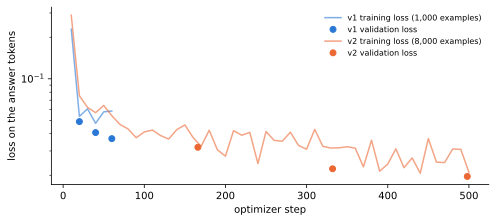

                               v1           v2
n_train                   1000.00      8000.00
optimizer steps             62.00       500.00
minutes                      2.20        14.90
peak GPU GB                  6.68         6.78
adapter MB                  73.90        73.90
trainable parameters  18464768.00  18464768.00


In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for (name, color), n in zip([("v1", "#2a78d6"), ("v2", "#eb6834")], [N_TRAIN_PILOT, N_TRAIN_FULL]):
    log = RUNS[name]["log"]
    tr, ev = log.dropna(subset=["loss"]), log.dropna(subset=["eval_loss"])
    ax.plot(tr["step"], tr["loss"], color=color, alpha=0.6, label=f"{name} training loss ({n:,} examples)")
    ax.plot(ev["step"], ev["eval_loss"], "o", color=color, label=f"{name} validation loss")
ax.set_xlabel("optimizer step")
ax.set_ylabel("loss on the answer tokens")
ax.set_yscale("log")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(pd.DataFrame({k: {m: v["record"][m] for m in ["n_train", "optimizer steps", "minutes", "peak GPU GB", "adapter MB",
                                                     "trainable parameters"]} for k, v in RUNS.items()}).to_string())

## 4. Does a candidate pass? The gate

Both adapters are loaded onto one copy of the base model (one adapter active at a time) and scored on the gate set
with the zero-shot prompt, the way lesson 4 scored them. The incumbent's answers are already in hand from section 1.
Two kinds of evidence are produced for each candidate: the metrics, and the verdict of each check in the table.

The gate is also run on a **control**: the worse of the two baselines as a pretend candidate against the incumbent. It has no
training behind it, so the gate must refuse it. A gate that cannot say no is not a gate.

In [14]:
base = load_base()
serving = PeftModel.from_pretrained(base, "adapters/v1", adapter_name="v1")
serving.load_adapter("adapters/v2", adapter_name="v2")
serving.eval()
for name in ["v1", "v2"]:
    serving.set_adapter(name)
    ANS[name], MS[name] = generate(serving, tok, [zero_shot(r) for r in gate])
    SCORED[name] = score(gate, ANS[name])
rep = pd.DataFrame({k: summary(SCORED[k]) for k in ["zero-shot", "3-shot", "v1", "v2"]}).T
rep["ms per example"] = pd.Series(MS)
rep["exec ±"] = [ci(rep.loc[k, "exec"], rep.loc[k, "n exec"]) for k in rep.index]
print(rep.round(3).to_string())

            runs  exact   exec  n exec  format ok  unsafe  ms per example  exec ±
zero-shot  0.962  0.584  0.616   450.0      0.938     0.0         126.925   0.045
3-shot     0.960  0.594  0.542   450.0      1.000     0.0         169.546   0.046
v1         0.978  0.676  0.793   450.0      1.000     0.0         221.859   0.037
v2         0.994  0.722  0.813   450.0      1.000     0.0         214.209   0.036


In [15]:
def run_gate(cand, incumbent):
    """Apply GATE to a candidate against the incumbent. Returns (passed, table of checks, details)."""
    c, b = SCORED[cand], SCORED[incumbent]
    ne = c["gold_nonempty"].values
    ce, be = c["exec"].values[ne], b["exec"].values[ne]
    only_c, only_b = int((ce & ~be).sum()), int((~ce & be).sum())
    gain = 100 * (ce.mean() - be.mean())
    p = sign_test_p(only_c, only_b)
    exact_gain = 100 * (c["exact"].mean() - b["exact"].mean())
    regress = only_b / max(int(be.sum()), 1)
    seg_drop = 0.0
    segs = {}
    for seg in sorted(set(c["segment"])):
        m = ne & (c["segment"].values == seg)
        segs[seg] = (m.sum(), 100 * c["exec"].values[m].mean(), 100 * b["exec"].values[m].mean())
        seg_drop = max(seg_drop, segs[seg][2] - segs[seg][1])
    s = summary(c)
    checks = [
        ("execution gain, points", f"{gain:+.1f}", f">= {GATE['min_exec_gain_points']}", gain >= GATE["min_exec_gain_points"]),
        ("sign test p (candidate better)", f"{p:.4f}", f"< {GATE['max_sign_test_p']}", p < GATE["max_sign_test_p"] and only_c > only_b),
        ("exact-match gain, points", f"{exact_gain:+.1f}", f">= {GATE['min_exact_gain_points']}", exact_gain >= GATE["min_exact_gain_points"]),
        ("regression share", f"{regress:.1%}", f"<= {GATE['max_regression_share']:.0%}", regress <= GATE["max_regression_share"]),
        ("well-formed replies", f"{s['format ok']:.1%}", f">= {GATE['min_format_ok']:.0%}", s["format ok"] >= GATE["min_format_ok"]),
        ("unsafe replies", f"{s['unsafe']}", f"<= {GATE['max_unsafe']}", s["unsafe"] <= GATE["max_unsafe"]),
        ("ms per example", f"{MS[cand]:.0f}", f"<= {GATE['max_ms_per_example']}", MS[cand] <= GATE["max_ms_per_example"]),
        ("worst segment drop, points", f"{seg_drop:.1f}", f"<= {GATE['max_segment_drop_points']}", seg_drop <= GATE["max_segment_drop_points"]),
    ]
    table = pd.DataFrame(checks, columns=["check", "measured", "threshold", "pass"])
    detail = {"exec gain points": gain, "only candidate right": only_c, "only incumbent right": only_b, "sign test p": p,
              "regression share": regress, "segments (n, candidate %, incumbent %)": segs}
    return bool(table["pass"].all()), table, detail


worse = [k for k in PROMPT if k != INCUMBENT][0]
GATE_RESULT = {}
for cand in ["v1", "v2", worse]:
    ok_, table_, detail = run_gate(cand, INCUMBENT)
    GATE_RESULT[cand] = {"passed": ok_, "checks": table_, "detail": detail}
    label = f"control ({worse} as candidate)" if cand == worse else f"candidate {cand}"
    print(f"\n=== {label} against incumbent {INCUMBENT}: {'PASS' if ok_ else 'FAIL'} ===")
    print(table_.to_string(index=False))
control_refused = not GATE_RESULT[worse]["passed"]
print("\nthe control was refused:", control_refused)
assert control_refused, "the gate accepted a candidate with no training behind it"


=== candidate v1 against incumbent zero-shot: PASS ===
                         check measured threshold  pass
        execution gain, points    +17.8    >= 5.0  True
sign test p (candidate better)   0.0000    < 0.05  True
      exact-match gain, points     +9.2    >= 0.0  True
              regression share     6.9%    <= 10%  True
           well-formed replies   100.0%    >= 99%  True
                unsafe replies        0      <= 0  True
                ms per example      222    <= 400  True
    worst segment drop, points      0.0    <= 3.0  True

=== candidate v2 against incumbent zero-shot: PASS ===
                         check measured threshold  pass
        execution gain, points    +19.8    >= 5.0  True
sign test p (candidate better)   0.0000    < 0.05  True
      exact-match gain, points    +13.8    >= 0.0  True
              regression share     9.7%    <= 10%  True
           well-formed replies   100.0%    >= 99%  True
                unsafe replies        0      <= 

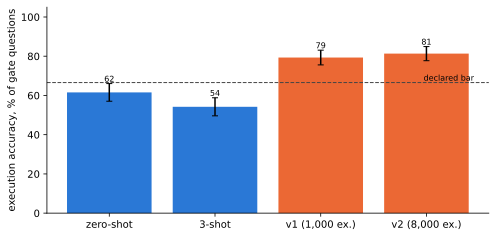

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.4))
names = ["zero-shot", "3-shot", "v1", "v2"]
labels = ["zero-shot", "3-shot", f"v1 ({N_TRAIN_PILOT:,} ex.)", f"v2 ({N_TRAIN_FULL:,} ex.)"]
vals = [100 * rep.loc[k, "exec"] for k in names]
errs = [100 * rep.loc[k, "exec ±"] for k in names]
ax.bar(range(4), vals, yerr=errs, capsize=3, color=["#2a78d6", "#2a78d6", "#eb6834", "#eb6834"])
ax.axhline(100 * BAR, color="#444", ls="--", lw=1)
ax.text(3.45, 100 * BAR + 1, "declared bar", ha="right", fontsize=8)
for i, v in enumerate(vals):
    ax.text(i, v + errs[i] + 1, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(range(4))
ax.set_xticklabels(labels)
ax.set_ylabel("execution accuracy, % of gate questions")
ax.set_ylim(0, 105)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Regression check, read by eye.** The table counted how many questions the incumbent answered correctly and the
candidate does not. Those are the cases a reviewer asks about first, so a few are printed. A release that only says
"better on average" has not looked at them.

In [17]:
passing = [k for k in ["v1", "v2"] if GATE_RESULT[k]["passed"]]
shown_for = passing[-1] if passing else "v2"
c, b = SCORED[shown_for], SCORED[INCUMBENT]
broken = c[(~c["exec"]) & b["exec"] & c["gold_nonempty"]].head(4)
print(f"{shown_for}: questions the incumbent got right and it did not (first 4 of {int(((~c['exec']) & b['exec'] & c['gold_nonempty']).sum())})\n")
for i, r in broken.iterrows():
    print("question :", gate[i]["question"])
    print("gold     :", gate[i]["answer"])
    print("incumbent:", b.loc[i, "sql"][:160].replace("\n", " "))
    print("candidate:", r["sql"][:160].replace("\n", " "), "\n")

# Pick the release candidate: the passing candidate with the highest execution accuracy; on a tie, the cheaper one.
if not passing:
    raise RuntimeError("No candidate passed the gate: the release stops here. This is the gate working; "
                       "the checks above say what to fix, and the next attempt gets a new gate file only by a recorded decision.")
PROMOTED = max(passing, key=lambda k: (summary(SCORED[k])["exec"], k == "v1"))
print(f"\nrelease candidate: {PROMOTED}; passed the gate: {passing}")

v2: questions the incumbent got right and it did not (first 4 of 27)

question : Name the latitude for deer lake
gold     : SELECT latitude FROM table_18600760_4 WHERE township = "Deer Lake"
incumbent: SELECT latitude FROM table_18600760_4 WHERE township = 'Deer Lake'
candidate: SELECT COUNT(latitude) FROM table_18600760_4 WHERE township = "Deer Lake" 

question : What unit of length is being used for the route with "replaced by us 81" in their remarks section?
gold     : SELECT length FROM table_11336756_6 WHERE remarks = "Replaced by US 81"
incumbent: SELECT length FROM table_11336756_6 WHERE remarks LIKE '%replaced by us 81%'
candidate: SELECT COUNT(length) FROM table_11336756_6 WHERE remarks = "Replaced by US 81" 

question : What was the date of the finale for Season 3?
gold     : SELECT finale FROM table_name_61 WHERE season = 3
incumbent: SELECT finale FROM table_name_61 WHERE season = '3'
candidate: SELECT finale FROM table_name_61 WHERE season = "season 3" 

question : Name th

## 5. What is released? The release record and the model card

Everything needed to audit or rebuild the release is written to one JSON file, and the part a person reads is written
as a model card from the same numbers. Two things are deliberately left empty: the **approval** fields. A notebook can
produce evidence; it cannot be the person who accepts the risk. The record is also given a manifest of file hashes, so
that a later edit of any record is visible.

In [18]:
def seg_table(cand):
    return {seg: {"n": int(n_), "candidate exec %": round(a, 1), "incumbent exec %": round(b_, 1)}
            for seg, (n_, a, b_) in GATE_RESULT[cand]["detail"]["segments (n, candidate %, incumbent %)"].items()}


run = RUNS[PROMOTED]["record"]
RECORD = {
    "release id": f"sql-assistant-{PROMOTED}-{time.strftime('%Y%m%d')}",
    "created (UTC)": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()),
    "status": "candidate: passed the gate, not yet canaried",
    "task": DECISION["task"],
    "intended use": "turn a plain-English question about a stated SQLite schema into one read-only SELECT query",
    "out of scope": ["any use without a read-only database connection", "schemas with many tables or joins across a dozen tables",
                     "languages other than English", "decisions made without a person reading the result"],
    "decision record": {"file": f"{RELEASE}/decision_record.json", "incumbent": INCUMBENT, "bar": round(BAR, 4)},
    "base model": {"id": MODEL_ID, "revision": BASE_REV, "licence": BASE_LICENCE},
    "data card": {"file": f"{RELEASE}/data_card.json", "sha256": DATA_CARD_SHA, "training data sha256": run["training data sha256"],
                  "gate set sha256": sha256_json([[r["id"], r["answer"]] for r in gate])},
    "training": {k: run[k] for k in ["n_train", "optimizer steps", "seed", "config sha256", "minutes", "peak GPU GB",
                                     "trainable parameters", "final train loss", "validation loss", "versions"]},
    "config file": f"runs/{PROMOTED}/config.json",
    "gate": {"file": f"{RELEASE}/gate.json", "sha256 (declared before training)": GATE_SHA,
             "checks": GATE_RESULT[PROMOTED]["checks"].astype(str).to_dict("records"), "passed": True,
             "control refused": control_refused, "sign test p": GATE_RESULT[PROMOTED]["detail"]["sign test p"]},
    "metrics (gate set)": {"incumbent": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                                         for k, v in summary(SCORED[INCUMBENT]).items()},
                           "candidate": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                                         for k, v in summary(SCORED[PROMOTED]).items()},
                           "segments": seg_table(PROMOTED), "n": N_GATE},
    "adapter": {"path": run["adapter path"], "sha256": run["adapter sha256"], "MB": run["adapter MB"]},
    "rollback target": INCUMBENT + " on the base model, no adapter",
    "known limits": ["scored on tables with synthetic rows, not on a customer's data",
                     "execution accuracy ignores column order differences only when the rows match exactly",
                     "gate set and training data come from the same two public benchmarks",
                     "no check of queries that are valid but slow on a large table"],
    "approval": {"owner": None, "risk reviewer": None, "date": None,
                 "note": "empty on purpose: a person fills this in; the notebook does not approve its own release"},
}
write_json(f"{RELEASE}/release_record.json", RECORD)

c_, i_ = RECORD["metrics (gate set)"]["candidate"], RECORD["metrics (gate set)"]["incumbent"]
CARD = f"""# Model card: {RECORD['release id']}

**Base model:** {MODEL_ID}, revision `{BASE_REV}`. **Adapter:** LoRA, {run['adapter MB']} MB, sha256 `{run['adapter sha256'][:16]}...`.

## Intended use
{RECORD['intended use']}.

## Out of scope
""" + "\n".join(f"- {x}" for x in RECORD["out of scope"]) + f"""

## Training data
{DATA_CARD['name']} at commit `{DATA_COMMIT[:10]}` ({DATA_CARD['licence']}). {run['n_train']:,} examples drawn from the training split; no table of the test split appears in it.
Training data sha256 `{run['training data sha256'][:16]}...`. Seed {SEED}. Config sha256 `{run['config sha256'][:16]}...`.

## Evaluation (gate set, {N_GATE} questions, populated tables)
| | execution accuracy | exact match | well-formed | unsafe |
|---|---|---|---|---|
| incumbent ({INCUMBENT}) | {i_['exec']:.1%} | {i_['exact']:.1%} | {i_['format ok']:.1%} | {i_['unsafe']} |
| this release | {c_['exec']:.1%} | {c_['exact']:.1%} | {c_['format ok']:.1%} | {c_['unsafe']} |

Gate thresholds were written before training (sha256 `{GATE_SHA[:16]}...`). Paired sign test p = {RECORD['gate']['sign test p']:.4f}.

## Known limits
""" + "\n".join(f"- {x}" for x in RECORD["known limits"]) + """

## Approval
Owner: ________  Risk reviewer: ________  Date: ________
"""
open(f"{RELEASE}/MODEL_CARD.md", "w").write(CARD)
print(CARD)

# Model card: sql-assistant-v2-20261126

**Base model:** Qwen/Qwen2.5-1.5B-Instruct, revision `989aa7980e4cf806f80c7fef2b1adb7bc71aa306`. **Adapter:** LoRA, 73.9 MB, sha256 `d7ba4d877b444d71...`.

## Intended use
turn a plain-English question about a stated SQLite schema into one read-only SELECT query.

## Out of scope
- any use without a read-only database connection
- schemas with many tables or joins across a dozen tables
- languages other than English
- decisions made without a person reading the result

## Training data
sql-create-context at commit `9d80a6a118` (CC BY 4.0 (dataset card at this commit); built from WikiSQL and Spider questions). 8,000 examples drawn from the training split; no table of the test split appears in it.
Training data sha256 `8c1c32a71c48a88b...`. Seed 42. Config sha256 `148bbee0b1d5f79e...`.

## Evaluation (gate set, 500 questions, populated tables)
| | execution accuracy | exact match | well-formed | unsafe |
|---|---|---|---|---|
| incumbent (zero-sho

## 6. Does it hold on traffic that looks different? Shadow and canary

The gate set is a benchmark. Live traffic has another mix, so a second held-out slice is used, drawn with more of one
kind of question than the benchmark has. Two things are simulated:

- **Shadow.** Every request is answered by both the incumbent and the candidate. Only the incumbent's answer would be
  served. The two are compared on signals that need no gold answer: does the query run, is it well formed, is it safe,
  how often do the two disagree.
- **Canary.** The candidate then serves a growing share of requests (a fixed hash of the request id decides which),
  in stages. After each stage, rules declared in the gate decide: advance, or roll back.

Real traffic has no gold answers on the day. Here they exist, so the second half of the cell plays the **delayed
labels** that arrive later and answers the question the guards cannot: is the candidate actually better on this mix?

In [19]:
serving.set_adapter(PROMOTED)
cand_ans, cand_ms = generate(serving, tok, [zero_shot(r) for r in canary])
with serving.disable_adapter():
    inc_ans, inc_ms = generate(serving, tok, [PROMPT[INCUMBENT](r) for r in canary])
CAN = {"incumbent": score(canary, inc_ans), PROMOTED: score(canary, cand_ans)}
agree = np.mean([normalise(clean_sql(a)) == normalise(clean_sql(b)) for a, b in zip(inc_ans, cand_ans)])
print(f"shadow: both systems answered {N_CANARY} requests; they gave the same query on {agree:.1%} of them")
print(f"ms per example: incumbent {inc_ms:.0f}, candidate {cand_ms:.0f}")
print(pd.DataFrame({k: summary(v) for k, v in CAN.items()}).T.round(3).to_string())

shadow: both systems answered 400 requests; they gave the same query on 62.5% of them
ms per example: incumbent 129, candidate 236
            runs  exact   exec  n exec  format ok  unsafe
incumbent  0.962  0.532  0.630   373.0       0.95     0.0
v2         0.995  0.692  0.788   373.0       1.00     0.0


In [20]:
STAGES = [("stage 1", 0.10, 0, N_CANARY // 4), ("stage 2", 0.50, N_CANARY // 4, N_CANARY // 2),
          ("stage 3", 1.00, N_CANARY // 2, N_CANARY)]
route = lambda i: int(sha256_bytes(f"request-{i}".encode())[:8], 16) / 16 ** 8        # a fixed number in [0, 1) per request id
G = GATE["canary"]
inc_df, cand_df = CAN["incumbent"], CAN[PROMOTED]
log, rolled_back = [], False
for name, share, lo, hi in STAGES:
    ids = [i for i in range(lo, hi) if route(i) < share]
    if not ids:
        log.append({"stage": name, "share of traffic": share, "requests to candidate": 0, "guards": "advance (no requests)"})
        continue
    c, b = cand_df.iloc[ids], inc_df.iloc[ids]
    ne = c["gold_nonempty"].values
    d = (c["exec"].values[ne].astype(int) - b["exec"].values[ne].astype(int))
    half = 1.96 * d.std(ddof=1) / math.sqrt(len(d)) if len(d) > 1 else float("nan")
    guards = {"unsafe": int(c["unsafe"].sum()), "well-formed": c["format_ok"].mean(), "runs drop, points": 100 * (b["runs"].mean() - c["runs"].mean())}
    ok_ = (guards["unsafe"] <= G["max_unsafe"] and guards["well-formed"] >= G["min_format_ok"]
           and guards["runs drop, points"] <= G["max_runs_drop_points"])
    log.append({"stage": name, "share of traffic": share, "requests to candidate": len(ids), "unsafe": guards["unsafe"],
                "well-formed": round(guards["well-formed"], 3), "runs drop, points": round(guards["runs drop, points"], 1),
                "guards": "advance" if ok_ else "ROLL BACK", "label gap, points": round(100 * d.mean(), 1) if len(d) else None,
                "label CI ±, points": round(100 * half, 1)})
    if not ok_:
        rolled_back = True
        break
print(pd.DataFrame(log).to_string(index=False))
print("\nThe last column is the point of the stage design: with few requests the interval is wide, so a canary can catch a")
print("broken model early but cannot certify an improvement. The improvement was certified by the gate and is re-checked below.")

  stage  share of traffic  requests to candidate  unsafe  well-formed  runs drop, points  guards  label gap, points  label CI ±, points
stage 1               0.1                      8       0          1.0                0.0 advance               37.5                35.9
stage 2               0.5                     52       0          1.0               -1.9 advance                4.3                13.3
stage 3               1.0                    200       0          1.0               -4.0 advance               17.6                 6.9

The last column is the point of the stage design: with few requests the interval is wide, so a canary can catch a
broken model early but cannot certify an improvement. The improvement was certified by the gate and is re-checked below.


canary slice, all 400 requests with delayed labels: candidate minus incumbent = +15.8 points (95% interval +10.8 to +20.9), questions only the candidate gets right 80, only the incumbent 21
                     segment   n  incumbent exec %  candidate exec %
 named tables (Spider style) 255              66.3              76.9
table_name_N (WikiSQL style) 118              55.9              83.1

canary outcome: promote to full traffic


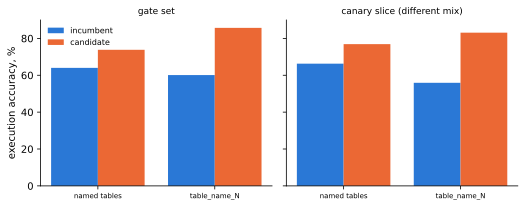

In [21]:
ne = cand_df["gold_nonempty"].values
d = cand_df["exec"].values[ne].astype(int) - inc_df["exec"].values[ne].astype(int)
diff, half = 100 * d.mean(), 100 * 1.96 * d.std(ddof=1) / math.sqrt(len(d))
only_c, only_b = int((d == 1).sum()), int((d == -1).sum())
seg_rows = []
for seg in sorted(set(cand_df["segment"])):
    m = ne & (cand_df["segment"].values == seg)
    seg_rows.append({"segment": seg, "n": int(m.sum()), "incumbent exec %": round(100 * inc_df["exec"].values[m].mean(), 1),
                     "candidate exec %": round(100 * cand_df["exec"].values[m].mean(), 1)})
print(f"canary slice, all {N_CANARY} requests with delayed labels: candidate minus incumbent = {diff:+.1f} points "
      f"(95% interval {diff - half:+.1f} to {diff + half:+.1f}), questions only the candidate gets right {only_c}, only the incumbent {only_b}")
print(pd.DataFrame(seg_rows).to_string(index=False))

CANARY_OK = (not rolled_back) and (diff - half >= G["min_paired_ci_low_points"])
CANARY = {"stages": log, "slice size": N_CANARY, "mix": pd.Series([r["segment"] for r in canary]).value_counts().to_dict(),
          "shadow agreement": float(agree), "label gap points": float(diff), "label CI half-width points": float(half),
          "segments": seg_rows, "rule": G, "outcome": "promote to full traffic" if CANARY_OK else "hold and roll back"}
print("\ncanary outcome:", CANARY["outcome"])

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.0), sharey=True)
gate_seg = RECORD["metrics (gate set)"]["segments"]
for ax, title, src in [(axes[0], "gate set", [(k, v["incumbent exec %"], v["candidate exec %"]) for k, v in gate_seg.items()]),
                       (axes[1], "canary slice (different mix)", [(r["segment"], r["incumbent exec %"], r["candidate exec %"]) for r in seg_rows])]:
    x = np.arange(len(src))
    ax.bar(x - 0.2, [s[1] for s in src], 0.4, color="#2a78d6", label="incumbent")
    ax.bar(x + 0.2, [s[2] for s in src], 0.4, color="#eb6834", label="candidate")
    ax.set_xticks(x)
    ax.set_xticklabels([s[0].split(" (")[0] for s in src], fontsize=7)
    ax.set_title(title, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("execution accuracy, %")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 7. Can we go back? Registry and rollback

A rollback that has never been run is a hope. The release is registered with two aliases, `production` and `previous`,
and each version stores what it needs to be rebuilt: the base revision, the adapter path and the adapter's hash. Three
things are then **checked, not assumed**:

1. **The candidate can be rebuilt from its records alone.** A fresh load, from the pinned base revision and the
   registered adapter (whose hash is verified before use), must give the same answers as were recorded when it was
   scored.
2. **Going back reproduces the old behaviour.** Flipping `production` to `previous` and serving it must give the
   answers recorded for the incumbent before any training happened.
3. **A damaged artefact is refused.** One byte of a copy of the adapter is changed; the loader must raise.

The comparison uses the first questions of the gate set, in the same batches as when they were scored, with greedy
decoding. A match is a byte-for-byte equal reply.

In [22]:
REGISTRY = {
    "base": {"id": MODEL_ID, "revision": BASE_REV},
    "versions": {
        INCUMBENT: {"kind": "prompt", "note": f"base model with the {INCUMBENT} prompt, no adapter",
                    "recorded probe digest": digest(ANS[INCUMBENT][:N_PROBE])},
        **{k: {"kind": "adapter", "path": RUNS[k]["record"]["adapter path"], "sha256": RUNS[k]["record"]["adapter sha256"],
               "recorded probe digest": digest(ANS[k][:N_PROBE]),
               "gate": "passed" if GATE_RESULT[k]["passed"] else "failed"} for k in ["v1", "v2"]},
    },
    "aliases": {"production": INCUMBENT, "previous": None},
    "history": [{"event": "registered", "alias production": INCUMBENT}],
}


def verify_adapter(path, expected):
    got = sha256_file(f"{path}/adapter_model.safetensors")
    if got != expected:
        raise ValueError(f"adapter at {path} does not match its registered hash")


def promote(version):
    """Move production to a version that passed the gate and the canary. The old production becomes 'previous'."""
    assert REGISTRY["versions"][version].get("gate") == "passed" and CANARY_OK, "only a version that passed may be promoted"
    REGISTRY["aliases"].update({"previous": REGISTRY["aliases"]["production"], "production": version})
    REGISTRY["history"].append({"event": "promoted", **REGISTRY["aliases"]})


def rollback():
    a = REGISTRY["aliases"]
    a["production"], a["previous"] = a["previous"], a["production"]
    REGISTRY["history"].append({"event": "rolled back", **a})


def load_version(vid):
    """Rebuild a version from the registry alone: pinned base revision, verified adapter. Returns (model, prompt builder)."""
    v = REGISTRY["versions"][vid]
    model = load_base().eval()
    if v["kind"] == "prompt":
        return model, PROMPT[vid]
    verify_adapter(v["path"], v["sha256"])
    return PeftModel.from_pretrained(model, v["path"]).eval(), zero_shot


if not CANARY_OK:
    raise RuntimeError("The canary did not clear: production stays on the incumbent and the release is held. This is the rule working.")
promote(PROMOTED)
print("aliases after promotion:", REGISTRY["aliases"])

aliases after promotion: {'production': 'v2', 'previous': 'zero-shot'}


In [23]:
def probe_match(answers, vid):
    """How many of the probe replies are byte-for-byte the ones recorded when the version was scored."""
    recorded = ANS[vid][:N_PROBE]
    same = sum(a == b for a, b in zip(answers, recorded))
    return same, digest(answers) == REGISTRY["versions"][vid]["recorded probe digest"]


checks = []
# 1. rebuild the promoted version from the registry alone (the training copy is freed first)
del serving, base
free_gpu()
model, build = load_version(REGISTRY["aliases"]["production"])
out, _ = generate(model, tok, [build(r) for r in probe])
same, whole = probe_match(out, PROMOTED)
checks.append({"check": f"fresh load of {PROMOTED} from registry reproduces its recorded replies", "same replies": f"{same} of {N_PROBE}", "digest equal": whole})

# 2a. roll back by switching the adapter off on the loaded model
with model.disable_adapter():
    out, _ = generate(model, tok, [PROMPT[INCUMBENT](r) for r in probe])
same, whole = probe_match(out, INCUMBENT)
checks.append({"check": f"adapter switched off reproduces {INCUMBENT} as recorded before training", "same replies": f"{same} of {N_PROBE}", "digest equal": whole})
del model
free_gpu()

# 2b. roll back by flipping the alias and loading the previous version from scratch
rollback()
model, build = load_version(REGISTRY["aliases"]["production"])
out, _ = generate(model, tok, [build(r) for r in probe])
same, whole = probe_match(out, REGISTRY["aliases"]["production"])
checks.append({"check": f"alias flipped to {REGISTRY['aliases']['production']}, fresh load reproduces its recorded replies", "same replies": f"{same} of {N_PROBE}", "digest equal": whole})
del model
free_gpu()

# 3. a damaged copy of the adapter must be refused
shutil.copytree(f"adapters/{PROMOTED}", "adapters/damaged", dirs_exist_ok=True)
with open("adapters/damaged/adapter_model.safetensors", "r+b") as f:
    f.seek(-1, os.SEEK_END)
    last = f.read(1)
    f.seek(-1, os.SEEK_END)
    f.write(bytes([last[0] ^ 1]))
try:
    verify_adapter("adapters/damaged", REGISTRY["versions"][PROMOTED]["sha256"])
    refused = False
except ValueError as e:
    refused = True
    print("loader said:", e)
checks.append({"check": "a copy of the adapter with one byte changed is refused", "same replies": "-", "digest equal": refused})
shutil.rmtree("adapters/damaged")
ROLLBACK = pd.DataFrame(checks)
print(ROLLBACK.to_string(index=False))
print("\nregistry after the rollback drill:", REGISTRY["aliases"])

loader said: adapter at adapters/damaged does not match its registered hash
                                                                 check same replies  digest equal
        fresh load of v2 from registry reproduces its recorded replies     96 of 96          True
 adapter switched off reproduces zero-shot as recorded before training     96 of 96          True
alias flipped to zero-shot, fresh load reproduces its recorded replies     96 of 96          True
                a copy of the adapter with one byte changed is refused            -          True

registry after the rollback drill: {'production': 'zero-shot', 'previous': 'v2'}


The drill rolled production back to the incumbent. For a real release the next step is the opposite flip, back to the
candidate, which only needs the alias to move: the check above shows that both versions rebuild from their records.
The final cell flips the alias again, completes the release record and verifies the manifest.

In [24]:
promote(PROMOTED)          # the drill is over: production is the released version again
write_json(f"{RELEASE}/registry.json", REGISTRY)
RECORD["status"] = "released to full traffic after canary" if CANARY_OK else "held: canary did not clear"
RECORD["canary"] = CANARY
RECORD["rollback drill"] = {"checks": ROLLBACK.astype(str).to_dict("records"), "registry": f"{RELEASE}/registry.json",
                            "drill complete": bool(ROLLBACK["digest equal"].all())}
RECORD["history"] = REGISTRY["history"]
write_json(f"{RELEASE}/release_record.json", RECORD)

CARD += f"""
## Canary and rollback
Canary slice of {N_CANARY} requests with a different mix: candidate minus incumbent {CANARY['label gap points']:+.1f} points
(95% interval half-width {CANARY['label CI half-width points']:.1f}); outcome: {CANARY['outcome']}.
Rollback drill: {'every check passed' if RECORD['rollback drill']['drill complete'] else 'a check FAILED, see the release record'}.
"""
open(f"{RELEASE}/MODEL_CARD.md", "w").write(CARD)

# A manifest of every record file, and a function that re-checks it.
FILES = ["decision_rule.json", "decision_record.json", "data_card.json", "gate.json", "registry.json", "release_record.json", "MODEL_CARD.md"]
MANIFEST = {f"{RELEASE}/{f}": sha256_file(f"{RELEASE}/{f}") for f in FILES}
MANIFEST.update({f"adapters/{k}/adapter_model.safetensors": RUNS[k]["record"]["adapter sha256"] for k in RUNS})
MANIFEST.update({f"runs/{k}/config.json": RUNS[k]["record"]["config sha256"] for k in RUNS})
write_json(f"{RELEASE}/MANIFEST.json", MANIFEST)


def verify_release():
    """Paths whose content no longer matches the hash in the manifest."""
    manifest = json.load(open(f"{RELEASE}/MANIFEST.json"))
    return [f for f, h in manifest.items() if sha256_file(f) != h]


print("manifest entries:", len(MANIFEST), "| files that do not match their hash:", verify_release())
assert verify_release() == []
with open(f"{RELEASE}/release_record.json", "a") as f:       # damage the record, and the manifest must notice
    f.write(" ")
print("after a one-character edit of the record:", verify_release())
assert verify_release() == [f"{RELEASE}/release_record.json"]
write_json(f"{RELEASE}/release_record.json", RECORD)         # restore it
assert verify_release() == []
print("restored; manifest verifies again")
for f in sorted(os.listdir(RELEASE)):
    print(f"{os.path.getsize(os.path.join(RELEASE, f)) / 1e3:8.1f} KB  {RELEASE}/{f}")
print("\nstatus:", RECORD["status"])
print("approval fields still empty:", RECORD["approval"])

manifest entries: 11 | files that do not match their hash: []


after a one-character edit of the record: ['release/release_record.json']


restored; manifest verifies again
     1.1 KB  release/MANIFEST.json
     1.8 KB  release/MODEL_CARD.md
     1.5 KB  release/data_card.json
     1.0 KB  release/decision_record.json
     0.5 KB  release/decision_rule.json
     0.4 KB  release/gate.json
     1.3 KB  release/registry.json
     6.6 KB  release/release_record.json

status: released to full traffic after canary
approval fields still empty: {'owner': None, 'risk reviewer': None, 'date': None, 'note': 'empty on purpose: a person fills this in; the notebook does not approve its own release'}


## Read the result

- **The decision came first.** The baselines were measured under a rule written before the measurement, so the choice to
  fine-tune is a recorded decision rather than a habit.
- **The gate said what a pass is before there was anything to pass.** The control candidate shows it can refuse, and
  each check protects something different: the gain, its luck, the questions that used to work, the format, the speed
  and the segments.
- **The record ties four things together:** the data hash, the config, the gate and the adapter hash, on a base model
  pinned to a revision. Change any one and the manifest says so.
- **A canary catches breakage, not improvement.** The stage table shows how wide the interval is when few requests reach
  the candidate. What the canary slice adds is a second look on a different mix.
- **Rollback was run, not described.** The previous version reproduced its recorded replies, and a damaged adapter was
  refused.
- **Approval is a person.** The fields are empty on purpose.

The lesson explains each step and the companies that learned the same things from production:
[Capstone: a governed release](https://docs.recohut.com/courses/llm-fine-tuning/4-ship/13-capstone).